# Three constructions on one class: compositions, partitions, distinct partitions

Start with the class $\mathcal I=\operatorname{SEQ}_{\ge1}(\mathcal Z)$ of positive integers: exactly one object of each size $n\ge1$, so
$$I(z)=z+z^2+z^3+\cdots=\frac{z}{1-z}.$$
Apply three different constructions to it:

* a **composition** of $n$ is a *sequence* of positive integers with sum $n$: $\ \mathcal C=\operatorname{SEQ}(\mathcal I)$;
* a **partition** of $n$ is a *multiset* of positive integers with sum $n$: $\ \mathcal P=\operatorname{MSET}(\mathcal I)$;
* a **partition of $n$ into distinct parts** is a *set* of positive integers with sum $n$: $\ \mathcal Q=\operatorname{PSET}(\mathcal I)$.

Their generating functions are
$$
C(z)=\frac{1}{1-I(z)},\qquad
P(z)=\prod_{k\ge1}\frac{1}{1-z^k},\qquad
Q(z)=\prod_{k\ge1}\left(1+z^k\right).
$$

Same atoms, three ways of combining them, and three very different growth rates. This notebook builds each series in Sage, expands it, checks it against brute-force enumeration, and plots the three sequences together. A fourth class joins at the end (October 30): the **plane trees**, counted by the Catalan numbers, whose specification is *recursive*, $\mathcal G=\mathcal Z\times\operatorname{SEQ}(\mathcal G)$, and whose growth is a third kind.

## Setup

We work in the ring $\mathbb Q[[z]]$ of formal power series, keeping coefficients through $z^N$. Everything Sage prints is exact up to the `O(z^...)` term, which marks where the information stops.

In [1]:
N = 60                                     # keep coefficients a_0, ..., a_N
R.<z> = PowerSeriesRing(QQ, default_prec=N + 1)

I = z / (1 - z)                            # SEQ_{>=1}(Z): one positive integer of each size
I.add_bigoh(12)                            # show just the first few terms

z + z^2 + z^3 + z^4 + z^5 + z^6 + z^7 + z^8 + z^9 + z^10 + z^11 + O(z^12)

## The constructions as operations on series

For a class $\mathcal A$ with no object of size $0$ (so $A(0)=0$):
$$
\operatorname{SEQ}(\mathcal A)\ \mapsto\ \frac{1}{1-A(z)},\qquad
\operatorname{MSET}(\mathcal A)\ \mapsto\ \exp\Big(\sum_{k\ge1}\frac{A(z^k)}{k}\Big),\qquad
\operatorname{PSET}(\mathcal A)\ \mapsto\ \exp\Big(\sum_{k\ge1}\frac{(-1)^{k-1}A(z^k)}{k}\Big).
$$
The $\exp$–$\log$ forms (FS Theorem I.1) work for *any* $\mathcal A$; they are what the product formulas become after taking logarithms. Since $A(z^k)=O(z^k)$, the terms with $k>N$ cannot affect $a_0,\dots,a_N$, so the sums are finite here.

In [2]:
def SEQ(A):
    assert A.valuation() > 0, "SEQ(A) needs A(0) = 0"
    return 1 / (1 - A)

def MSET(A):
    assert A.valuation() > 0, "MSET(A) needs A(0) = 0"
    return sum(A(z^k) / k for k in range(1, N + 1)).exp()

def PSET(A):
    assert A.valuation() > 0, "PSET(A) needs A(0) = 0"
    return sum((-1)^(k - 1) * A(z^k) / k for k in range(1, N + 1)).exp()

## 1. Compositions: $\operatorname{SEQ}(\mathcal I)$

In [3]:
C = SEQ(I)
C.add_bigoh(12)

1 + z + 2*z^2 + 4*z^3 + 8*z^4 + 16*z^5 + 32*z^6 + 64*z^7 + 128*z^8 + 256*z^9 + 512*z^10 + 1024*z^11 + O(z^12)

Because $I(z)$ is rational, so is $C(z)$, and we can see its closed form by doing the same computation with rational functions instead of power series:

In [4]:
F.<x> = FractionField(QQ['x'])
C_closed = 1 / (1 - x / (1 - x))          # the same algebra, done with rational functions
print(C_closed == (1 - x) / (1 - 2*x))
print((1 - z) / (1 - 2*z) == C)             # and its expansion is the series above

True
True


So $C(z)=\dfrac{1-z}{1-2z}=1+\dfrac{z}{1-2z}$, and $c_n=2^{n-1}$ for $n\ge1$ (the dots-and-bars count: $n-1$ gaps, each with or without a bar). Check against the formula and against Sage's own enumeration:

In [5]:
print(all(C[n] == 2^(n - 1) for n in range(1, N + 1)))
print(all(C[n] == Compositions(n).cardinality() for n in range(0, 13)))
Compositions(4).list()

True
True


[[1, 1, 1, 1], [1, 1, 2], [1, 2, 1], [1, 3], [2, 1, 1], [2, 2], [3, 1], [4]]

## 2. Partitions: $\operatorname{MSET}(\mathcal I)$

Partitions are not rational, so here the series *is* the answer. Build it two ways: from the general $\operatorname{MSET}$ operator, and as Euler's product $\prod_k (1-z^k)^{-1}$, one geometric series per part size (choose how many copies of $k$ to use).

In [6]:
P = MSET(I)
P_product = prod(1 / (1 - z^k) for k in range(1, N + 1))
print("MSET(I) == Euler product:", P == P_product)
P.add_bigoh(16)

MSET(I) == Euler product: True


1 + z + 2*z^2 + 3*z^3 + 5*z^4 + 7*z^5 + 11*z^6 + 15*z^7 + 22*z^8 + 30*z^9 + 42*z^10 + 56*z^11 + 77*z^12 + 101*z^13 + 135*z^14 + 176*z^15 + O(z^16)

In [7]:
print(all(P[n] == Partitions(n).cardinality() for n in range(0, N + 1)))
Partitions(6).list()

True


[[6], [5, 1], [4, 2], [4, 1, 1], [3, 3], [3, 2, 1], [3, 1, 1, 1], [2, 2, 2], [2, 2, 1, 1], [2, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]]

## 3. Partitions into distinct parts: $\operatorname{PSET}(\mathcal I)$

Now each part size is used at most once: one factor $1+z^k$ per size. Euler's theorem from class says the same series counts partitions into **odd** parts, $\prod_k (1-z^{2k-1})^{-1}$; the two products agree because $1+z^k=(1-z^{2k})/(1-z^k)$, and everything cancels except the odd denominators.

In [8]:
Q = PSET(I)
Q_product = prod(1 + z^k for k in range(1, N + 1))
Q_odd = prod(1 / (1 - z^k) for k in range(1, N + 1, 2))
print("PSET(I) == prod (1 + z^k):", Q == Q_product)
print("            == odd parts: ", Q == Q_odd)
Q.add_bigoh(16)

PSET(I) == prod (1 + z^k): True
            == odd parts:  True


1 + z + z^2 + 2*z^3 + 2*z^4 + 3*z^5 + 4*z^6 + 5*z^7 + 6*z^8 + 8*z^9 + 10*z^10 + 12*z^11 + 15*z^12 + 18*z^13 + 22*z^14 + 27*z^15 + O(z^16)

In [9]:
distinct = lambda n: Partitions(n, max_slope=-1)           # each part strictly smaller than the last
odd      = lambda n: Partitions(n, parts_in=range(1, n + 1, 2))
print(all(Q[n] == distinct(n).cardinality() == odd(n).cardinality() for n in range(0, 31)))
print("distinct:", distinct(6).list())
print("odd:     ", odd(6).list())

True
distinct: [[6], [5, 1], [4, 2], [3, 2, 1]]
odd:      [[5, 1], [3, 3], [3, 1, 1, 1], [1, 1, 1, 1, 1, 1]]


## 4. Plane trees and the Catalan numbers: a recursive specification

A plane tree is a root with a sequence of plane trees attached: $\mathcal G=\mathcal Z\times\operatorname{SEQ}(\mathcal G)$, so
$$G(z)=\frac{z}{1-G(z)},\qquad\text{i.e.}\qquad G^2-G+z=0,\qquad G(z)=\frac{1-\sqrt{1-4z}}{2}.$$
Unlike the other three, this specification mentions the class on both sides, so there are two ways to get the series. **Iterate** $G_{k+1}=z/(1-G_k)$ from $G_0=0$: each round fixes one more coefficient. Or **solve** with the quadratic formula, choosing the root with $G(0)=0$. Sage's `sqrt` of a power series is Newton's binomial series, so the second route is $G=\sum_k\frac1k\binom{2k-2}{k-1}z^k$: the number of plane trees with $n$ nodes is the Catalan number $C_{n-1}$.

In [10]:
Gi = O(z^(N + 1))                     # iterate from "0, known to O(z^{N+1})" -- never from an exact 0
for k in range(N + 1):
    Gi = z / (1 - Gi)
Gq = (1 - (1 - 4*z).sqrt()) / 2            # the quadratic formula
print("iteration == quadratic formula:", Gi == Gq)
Gq.add_bigoh(12)

iteration == quadratic formula: True


z + z^2 + 2*z^3 + 5*z^4 + 14*z^5 + 42*z^6 + 132*z^7 + 429*z^8 + 1430*z^9 + 4862*z^10 + 16796*z^11 + O(z^12)

In [11]:
T = Gq                                      # plane trees, size = number of nodes
cat = [catalan_number(n) for n in range(N)]
print(all(T[n] == cat[n - 1] for n in range(1, N + 1)))
print("plane trees with 1..10 nodes:", [T[n] for n in range(1, 11)])

True
plane trees with 1..10 nodes: [1, 1, 2, 5, 14, 42, 132, 429, 1430, 4862]


Newton's binomial theorem is what `sqrt` is doing: $(1+x)^{\alpha}=\sum_k\binom{\alpha}{k}x^k$ for any rational $\alpha$, and with $\alpha=\tfrac12$, $x=-4z$ the coefficient $\binom{1/2}{k}(-4)^k$ simplifies to $-\frac2k\binom{2k-2}{k-1}$. Check Sage against the formula:

In [12]:
print([binomial(1/2, k) * (-4)^k for k in range(1, 7)])
print([-2/k * binomial(2*k - 2, k - 1) for k in range(1, 7)])

[-2, -2, -4, -10, -28, -84]
[-2, -2, -4, -10, -28, -84]


## The three sequences side by side

In [13]:
rows = [["$n$", "compositions $c_n$", "partitions $p_n$", "distinct parts $q_n$", "plane trees $t_n = C_{n-1}$"]]
rows += [[n, C[n], P[n], Q[n], T[n]] for n in range(0, 16)]
table(rows, header_row=True)

\(n\),compositions \(c_n\),partitions \(p_n\),distinct parts \(q_n\),plane trees \(t_n = C_{n-1}\)
\(0\),\(1\),\(1\),\(1\),\(0\)
\(1\),\(1\),\(1\),\(1\),\(1\)
\(2\),\(2\),\(2\),\(1\),\(1\)
\(3\),\(4\),\(3\),\(2\),\(2\)
\(4\),\(8\),\(5\),\(2\),\(5\)
\(5\),\(16\),\(7\),\(3\),\(14\)
\(6\),\(32\),\(11\),\(4\),\(42\)
\(7\),\(64\),\(15\),\(5\),\(132\)
\(8\),\(128\),\(22\),\(6\),\(429\)
\(9\),\(256\),\(30\),\(8\),\(1430\)


## Plot

The counts span many orders of magnitude, so the vertical axis is logarithmic. On that scale $c_n=2^{n-1}$ is a straight line of slope $\log_{10}2$, while $p_n$ and $q_n$ bend over: they grow faster than any polynomial but slower than any exponential $\gamma^n$ with $\gamma>1$. The plane trees are a second straight line, steeper (slope $\log_{10}4$), bending slightly *downward*: $t_n\sim 4^{n}/(4\sqrt\pi\,n^{3/2})$, and the $n^{-3/2}$ is visible as the gap below the line $4^n$.

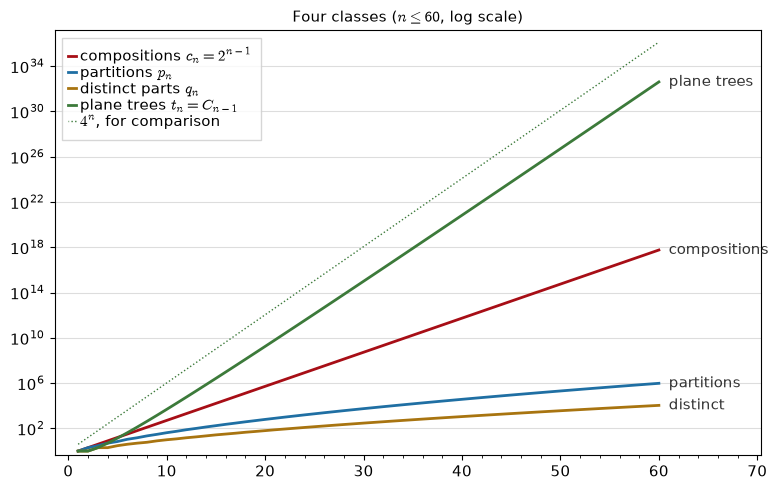

In [14]:
colors = {"comp": "#A70E16", "part": "#1F6FA3", "dist": "#A87410", "tree": "#3C7A3A"}
ns = range(1, N + 1)

def series_plot(S, color, label):
    return list_plot([(n, S[n]) for n in ns], plotjoined=True, color=color,
                     thickness=2, legend_label=label)

G  = series_plot(C, colors["comp"], r"compositions $c_n = 2^{n-1}$")
G += series_plot(P, colors["part"], r"partitions $p_n$")
G += series_plot(Q, colors["dist"], r"distinct parts $q_n$")
G += series_plot(T, colors["tree"], r"plane trees $t_n = C_{n-1}$")
G += list_plot([(n, 4^n) for n in ns], plotjoined=True, color=colors["tree"], linestyle=":", thickness=1,
               legend_label=r"$4^n$, for comparison")

# direct labels at the right-hand end of each curve
G += text("compositions", (N + 1, C[N]), color="#333333", horizontal_alignment="left", fontsize=11)
G += text("partitions",   (N + 1, P[N]), color="#333333", horizontal_alignment="left", fontsize=11)
G += text("distinct",     (N + 1, Q[N]), color="#333333", horizontal_alignment="left", fontsize=11)
G += text("plane trees",  (N + 1, T[N]), color="#333333", horizontal_alignment="left", fontsize=11)

G.set_legend_options(loc="upper left", font_size=11, shadow=False, back_color="white")
G.show(scale="semilogy", frame=True, axes=False, gridlines=[None, "major"],
       gridlinesstyle=dict(color="#dddddd", linestyle="-"),
       axes_labels_size=1, fontsize=11, xmin=0, xmax=N + 9, ymin=0.5, ymax=10 * 4^N,
       title=r"Four classes ($n \leq %d$, log scale)" % N,
       figsize=[8, 5])

## Where the growth rates come from

The growth rate is read off from where the generating function stops converging, which is the subject of the analytic half of the course:

* $C(z)=\dfrac{1-z}{1-2z}$ blows up first at $z=\tfrac12$, so $c_n\approx 2^n$.
* $G(z)=\frac{1-\sqrt{1-4z}}2$ stops being analytic at $z=\tfrac14$, where the square root has a branch point, so $t_n\approx4^n$; the square root, rather than a pole, is what produces the $n^{-3/2}$.
* $P(z)$ and $Q(z)$ converge on the whole open unit disk and go bad only at $|z|=1$, so they grow slower than every $\gamma^n$ with $\gamma>1$. The truth (Hardy–Ramanujan) is $\log p_n\sim\pi\sqrt{2n/3}$ and $\log q_n\sim\pi\sqrt{n/3}$.

You can see the square roots directly: plotted against $\sqrt n$, the logarithms of $p_n$ and $q_n$ are nearly straight lines, with slopes approaching $\pi\sqrt{2/3}\approx2.57$ and $\pi/\sqrt3\approx1.81$.

In [15]:
for name, S, c in [("partitions", P, pi * sqrt(2/3)), ("distinct parts", Q, pi / sqrt(3))]:
    slope = (log(S[N]) - log(S[N // 2])) / (sqrt(N) - sqrt(N // 2))
    print("%-15s  slope of log a_n vs sqrt(n) on [%d, %d]: %.3f   (limit %.3f)"
          % (name, N // 2, N, RR(slope), RR(c)))

partitions       slope of log a_n vs sqrt(n) on [30, 60]: 2.270   (limit 2.565)
distinct parts   slope of log a_n vs sqrt(n) on [30, 60]: 1.589   (limit 1.814)


The slopes are still well below their limits at $n=60$: the lower-order terms ($p_n\sim e^{\pi\sqrt{2n/3}}/(4n\sqrt3)$) matter for a long time. Try `N = 200` in the setup cell and run everything again; past that the `exp` inside `MSET` and `PSET` gets slow (about 20 seconds each at `N = 250`). The figure at the end of the notebook goes much further by a cheaper route.

**Things to try.**
1. Partitions with all parts at most $3$: replace $\mathcal I$ by $\mathcal Z+\mathcal Z^2+\mathcal Z^3$ (the series `z + z^2 + z^3`) and apply `MSET`. Is the result rational? What is its growth?
2. Binary partitions: let $\mathcal B$ be the powers of $2$, with series `sum(z^(2^j) for j in range(6))`. Compare `MSET(B)` with `PSET(B)`. One of them is a series you have known for a long time; why?
3. Compositions into odd parts: `SEQ(z/(1 - z^2))`. Which famous sequence appears?
4. Binary trees, $\mathcal B=\varepsilon+\mathcal Z\times\mathcal B\times\mathcal B$: iterate `B = 1 + z*B^2` from `O(z^N)`... or from `1 + O(z^N)`? Which starting point is right, and why? Compare with `Gq / z`.

## Measuring the corrections: $\log p_n/\sqrt n$, $\log q_n/\sqrt n$, and $n\,(1-t_{n+1}/4t_n)$

If $\log p_n\sim\pi\sqrt{2n/3}$, then $\log p_n/\sqrt n$ should level off at $\pi\sqrt{2/3}$, and likewise $\log q_n/\sqrt n\to\pi/\sqrt3$. (We plot the logarithm: $p_n/\sqrt n$ itself still grows like $e^{c\sqrt n}$.) To see far past $N$, this figure computes its own $p_n$ and $q_n$ for $n\le M=5000$ from Euler's product $\prod_k(1-z^k)^{-1}$ and the odd-parts product $\prod_{k\text{ odd}}(1-z^k)^{-1}$, with integer coefficients. That takes about 20 seconds; the `exp` route would take hours. The horizontal axis is logarithmic so that both the small-$n$ start and the long approach are visible. Each panel shows the data (solid), the limit (dashed), and the full Hardy–Ramanujan asymptotic formula (dotted),
$$
p_n\sim\frac{e^{\pi\sqrt{2n/3}}}{4\sqrt3\,n},\qquad q_n\sim\frac{e^{\pi\sqrt{n/3}}}{4\cdot3^{1/4}\,n^{3/4}}.
$$
The data hug the dotted curves, so the slow approach to the limit is the polynomial prefactor: it contributes a $-\log n/\sqrt n$ correction, which dies very slowly.

The third panel is the plane trees. If $t_n\approx K\cdot4^n n^{-\alpha}$ then $t_{n+1}/t_n\approx4(1-\alpha/n)$, so $n\,(1-\tfrac14 t_{n+1}/t_n)\to\alpha$; the panel shows that quantity approaching $\alpha=\tfrac32$ (exactly, $t_{n+1}/t_n=2(2n-1)/(n+1)$, so $n(1-\tfrac14t_{n+1}/t_n)=\tfrac{3n}{2(n+1)}$). The ratio test for the growth rate $4$ converges only like $1/n$, and the $3/2$ is what the square-root singularity will predict in Act III.

agrees with P and Q through n = N: True


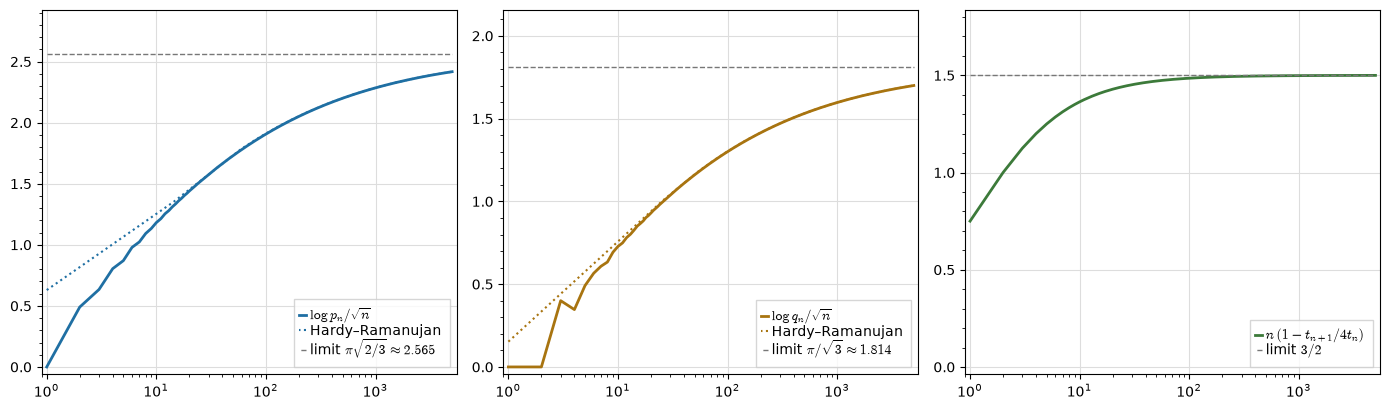

In [16]:
M = 5000                                   # how far this figure goes (~20 s; M = 10000 takes ~1.5 min)
S.<w> = PowerSeriesRing(ZZ, default_prec=M + 1)
P_big = prod(1 / (1 - w^k) for k in range(1, M + 1))       # Euler's product
Q_big = prod(1 / (1 - w^k) for k in range(1, M + 1, 2))    # odd parts = distinct parts
print("agrees with P and Q through n = N:", all(P_big[n] == P[n] and Q_big[n] == Q[n] for n in range(N + 1)))

def sqrt_scale_plot(A, color, name, c, c_tex, log_asymptotic):
    data = [(n, RDF(A[n]).log() / RDF(n).sqrt()) for n in range(1, M + 1)]
    G  = list_plot(data, plotjoined=True, color=color, thickness=2,
                   legend_label=r"$\log %s_n/\sqrt{n}$" % name)
    G += plot(lambda t: log_asymptotic(RDF(t)) / RDF(t).sqrt(), (1, M), color=color,
              linestyle=":", thickness=1.5, legend_label="Hardy–Ramanujan")
    G += line([(1, c), (M, c)], color="#777777", linestyle="--", thickness=1,
              legend_label=r"limit $%s \approx %.3f$" % (c_tex, RR(c)))
    G.set_legend_options(loc="lower right", font_size=10, shadow=False, back_color="white")
    G.set_axes_range(xmin=1, xmax=M, ymin=0, ymax=RR(c) + 0.3)
    return G

Gp = sqrt_scale_plot(P_big, colors["part"], "p", pi * sqrt(2/3), r"\pi\sqrt{2/3}",
                     lambda t: pi.n() * (2 * t / 3).sqrt() - (4 * RDF(3).sqrt() * t).log())
Gq = sqrt_scale_plot(Q_big, colors["dist"], "q", pi / sqrt(3), r"\pi/\sqrt{3}",
                     lambda t: pi.n() * (t / 3).sqrt() - (4 * RDF(3)^(1/4) * t^(3/4)).log())

T_big = (1 - (1 - 4*w).sqrt()) / 2                        # plane trees, n <= M, exact
tdata = [(n, RDF(n) * (1 - RDF(T_big[n + 1] / T_big[n]) / 4)) for n in range(1, M)]
Gt  = list_plot(tdata, plotjoined=True, color=colors["tree"], thickness=2,
                legend_label=r"$n\,(1 - t_{n+1}/4t_n)$")
Gt += line([(1, 1.5), (M, 1.5)], color="#777777", linestyle="--", thickness=1, legend_label=r"limit $3/2$")
Gt.set_legend_options(loc="lower right", font_size=10, shadow=False, back_color="white")
Gt.set_axes_range(xmin=1, xmax=M, ymin=0, ymax=1.8)

graphics_array([Gp, Gq, Gt]).show(scale="semilogx", frame=True, axes=False, gridlines=["major", "major"],
                                  gridlinesstyle=dict(color="#dddddd", linestyle="-"),
                                  fontsize=10, figsize=[14, 4.2])